FSM

(Q, Σ, q0, F, δ)

- Q: set of all states
- Σ: inputs
- q0: start / initial state
- F: Final State
- δ: Transition fxn,
- f: Q × Σ → Q   function


Regular languages: language recognized by FSM

Not Regular: - not recognized by FSM
             - cannot store or count strings

NFA: given same input & state you transition to different [states]
the mapping NFA: Σ × Q → Q is not a function

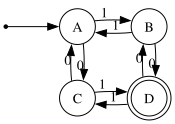

In [41]:
from graphviz import Digraph

fsm = Digraph('FSM', format='png')
fsm.attr(rankdir='LR')
fsm.engine = 'neato'  # Required for using pos attribute

# Define nodes with positions (x,y)
fsm.node('start', shape='point', pos='0,1!')
fsm.node('A', shape='circle', pos='1,1!')
fsm.node('B', shape='circle', pos='2,1!')
fsm.node('C', shape='circle', pos='1,0!')
fsm.node('D', shape='doublecircle', pos='2,0!')

# Edges
fsm.edge('start', 'A')
fsm.edge('A', 'B', label='1')
fsm.edge('B', 'A', label='1')
fsm.edge('B', 'D', label='0')
fsm.edge('D', 'B', label='0')
fsm.edge('C', 'D', label='1')
fsm.edge('D', 'C', label='1')
fsm.edge('C', 'A', label='0')
fsm.edge('A', 'C', label='0')

fsm

# fsm.render('fsm', format='png', cleanup=True)

# Finite Automata with Outputs

## Mealy Machine
**Tuple:** `(Q, Σ, Δ, δ, λ, q0)`

**Where**
- `Q` — finite set of states  
- `Σ` — finite, non-empty input alphabet  
- `Δ` — output alphabet  
- `δ : Q × Σ → Q` — transition function  
- `λ : Q × Σ → Δ` — output function (depends on *state and input*)  
- `q0` — initial/start state

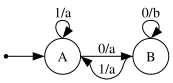

In [65]:
from graphviz import Digraph

g = Digraph('Mealy', format='png')
g.attr(rankdir='LR')
g.node('start', shape='point', pos='-1,0!', pin='true')
g.node('A', shape='circle',  pos='0,0!',  pin='true')
g.node('B', shape='circle',  pos='3,0!',  pin='true')

g.edge('start:e', 'A:w')

g.edge('A:n', 'A:n', label='1/a')
g.edge('A:e', 'B:w', label='0/a')
g.edge('B:n', 'B:n', label='0/b')
g.edge('B:w', 'A:e', label='1/a')

g  # or g.render('mealy', view=True)

## Moore Machine
**Tuple:** `(Q, Σ, Δ, δ, λ, q0)`

**Where**
- `Q` — finite set of states  
- `Σ` — finite, non-empty input alphabet  
- `Δ` — output alphabet  
- `δ : Q × Σ → Q` — transition function  
- `λ : Q → Δ` — output function (depends on *state only*)  
- `q0` — initial/start state

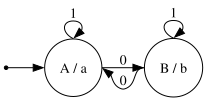

In [66]:
from graphviz import Digraph

# Moore machine in your style (ports + pinned nodes, LR layout)
g = Digraph('Moore', format='png')
g.attr(rankdir='LR')

# nodes (outputs shown in-state)
g.node('start', shape='point', pos='-1,0!', pin='true')
g.node('A', label='A / a', shape='circle', pos='0,0!',  pin='true')
g.node('B', label='B / b', shape='circle', pos='3,0!',  pin='true')

# start arrow (east of start -> west of A)
g.edge('start:e', 'A:w')

# self-loops on the north (input 1)
g.edge('A:n', 'A:n', label='1')
g.edge('B:n', 'B:n', label='1')

# cross transitions (input 0)
g.edge('A:e', 'B:w', label='0')
g.edge('B:w', 'A:e', label='0')

g

## Quick distinctions
- **Mealy:** output is `λ(state, input)` → label outputs on **edges**.
- - output is a function of (state, input) and is placed on edges.
- **Moore:** output is `λ(state)` → label outputs **inside states**.
- - output is a function of (state only) and is placed inside states.

# Regular Expression
Regular Expression are used for representing certain sets of strings in an algebraic fashion.
1) Any terminal symbol i.e. symbols ∈ Σ including ε & Φ are regular expressions
2) The Union of 2 regular expressions is also a regular expression
3) The concatenation of 2 regular expressions is also a regular expression
4) The iteration (or closure) of a regular expression is also a regular expression
5) The regular expression over Σ are precisely those obtained recursively by
   the application of above rules on several times.
- - **Definition by building rules.** A “regular expression over Σ” is **exactly** anything you can build from the base pieces  
  `∅`, `ε`, and every symbol `a ∈ Σ`,
  using only these constructors **any finite number of times**:
  - - union `|`, concatenation (juxtaposition), and Kleene star `*`.
- - **“Recursively / several times.”** Start with small regexes and keep combining them with `|`, concatenation, and `*`—repeat as needed, but only finitely many steps.
- - **“Precisely / smallest closed set.”** If something can’t be obtained by those steps, it’s **not** a formal regex (e.g., PCRE backreferences). This clause also enables **structural induction** proofs: prove base cases and show the property is preserved by the three constructors.

**Tiny example:** build `(a|b)*ab`
  1. `a`, `b` (base)
  2. `(a|b)` (union)
  3. `(a|b)*` (Kleene star)
  4. `(a|b)* a b` → `(a|b)*ab` (two concatenations)

## Identities of Regular Expressions

### Symbols
- `R, P, Q` — arbitrary regular expressions over the same alphabet `Σ`
- `∅` — empty language (matches nothing)
- `ε` — empty string (length 0)
- `+` — union / alternation (many texts use `|`)
- Juxtaposition `RS` — concatenation
- `R*` — Kleene star (zero or more concatenations of strings from `R`)
- `L(R)` — language denoted by regex `R`

Semantics you can use:
- `L(∅)=∅`, `L(ε)={ε}`, `L(a)={"a"}` for `a∈Σ`
- `L(R+S)=L(R)∪L(S)`, `L(RS)=L(R)·L(S)`, `L(R*)=(L(R))*`

- **Language (over Σ):** any subset of Σ* (a set of strings); it may include the empty string **ε**.
- **Empty language (∅):** the empty subset of Σ*—it contains **no** strings at all (so `{ε} ≠ ∅`).

### Identities

1) **`∅ + R = R`**  
   Union with the empty set changes nothing: `∅ ∪ L(R) = L(R)`.

2) **`∅R = R∅ = ∅`**  
   No concatenations possible because one side is empty.

3) **`εR = Rε = R`**  
   `{ε}` is the identity for concatenation.

4) **`ε* = ε` and `∅* = ε`**  
   Zero or more copies of `ε` is just `ε`; zero or more copies of `∅` can only be zero copies.

5) **`R + R = R`** *(idempotence of union)*  
   `L(R) ∪ L(R) = L(R)`.

6) **`RR* = R*` and `R*R = R*`**  
   Both sides denote “zero or more `R`” (every nonempty word in `R*` starts/ends with an `R`, and `ε∈R*`).

7) **`RR* = R*R`**  
   Follows from (6); both equal `R*`.

8) **`(R*)* = R*`**  
   Star is idempotent.

9) **`R* = ε + RR* = ε + R*R`**  
   Unfolding laws: every `R*` word is either `ε` or an `R` followed/preceded by another `R*` word.
   (`+` is union.)

10) **`(PQ)* P = P (QP)*`**  
    Regroup the blocks: `(PQ)^k P = P (QP)^k`.

11) **`(P + Q)* = (P* Q*)* = (Q* P*)*`**  
    Any string built from `P`/`Q` blocks can be segmented into alternating runs; each run is in `P*` or `Q*`.

12) **Distributivity:**  
    **(a)** `(P + Q)R = PR + QR`  
    **(b)** `R(P + Q) = RP + RQ`  
    Concatenation distributes over union on both sides.


### Notes
- Operator precedence: `*` > concatenation > `+`.  
- These laws live in **Kleene algebra**; they’re valid because they hold for the underlying languages via the semantics above.

# Regular Grammar

Grammar is a set of rules that we use for proper conversation with each other.  
In programming it is a mathematical set of rules to write programming languages in the correct way.

4 types of Grammar

| Grammar Type | Grammar Accepted | Language Accepted | Automaton |
|---|---|---|---|
| Type-0 | Unrestricted Grammar | Recursive Enumerable Language | Turing Machine |
| Type-1 | Context Sensitive Grammar | Context Sensitive Language | Linear bound Automaton |
| Type-2 | Context Sensitive Grammar | Content Free Language | Push down Automaton |
| Type-3 | Regular Grammar | Regular Language | Finite State Machine |

---

## What is an automaton?

An **automaton** (plural **automata**) is a mathematical model of computation that processes strings over an input alphabet by moving through a finite set of **states** according to a **transition rule**. A string is **accepted** if, after reading all symbols, the machine is in an accepting state.

**Typical components (for a DFA):** `A = (Q, Σ, δ, q0, F)`
- `Q`: finite set of states  
- `Σ`: input alphabet  
- `δ : Q × Σ → Q`: transition function  
- `q0 ∈ Q`: start state  
- `F ⊆ Q`: set of accepting states

**Link to the table above:**
- **Finite State Machine** recognizes **Regular Language** (Type-3)  
- **Push down Automaton** recognizes **Content Free Language** (Type-2)  
- **Linear bound Automaton** recognizes **Context Sensitive Language** (Type-1)  
- **Turing Machine** recognizes **Recursive Enumerable Language** (Type-0)

# Grammar

A Grammar 'G' can be formally described using 4 tuples as  
**G = (V, T, S, P)** where

- **V**: set of Variables or Non-Terminal Symbols  
- **T**: Set of Terminal Symbols  
- **S**: Start Symbol  
- **P**: Production rules for Terminal & non-Terminals

A production rules has the form **α → β** where **α** and **β** are strings on **V ∪ T** and at least one symbol of **α** belongs to **V**.

**Eg:**  
G = ( {S, A, B}, {a, b}, S, { S → AB, A → a, B → b } )

### What is `T` in a grammar?

**TL;DR:** `T` is the **terminal alphabet**—the finite set of symbols a grammar ultimately produces; every generated string is in `T*`.

**Formal role (for `G = (V, T, S, P)`):**
- `T` is a **finite set of terminals** (atomic output symbols).  
- `V` is a disjoint set of **nonterminals** (`V ∩ T = ∅`).  
- **Productions** in `P` may have terminals on the **right** but **never** put a terminal on the **left** of `→`.  
- The **language** of the grammar is `L(G) ⊆ T*` (only terminals appear in final strings).

**Operational intuition:**
- In derivations, terminals are **never rewritten**; only nonterminals expand.  
- You **stop** deriving when the sentential form contains **no** symbols from `V` (i.e., it lies in `T*`).

**Automata link:**  
When you turn a regular grammar into a finite automaton, the automaton’s input alphabet `Σ` is (up to notation) **the same set as `T`**—these are exactly the symbols the machine reads.

**Example:**
- `G = ( V={S,A}, T={a,b}, S, P )`, with rules `S → aA | b`, `A → aA | b`.  
  Derivation: `S ⇒ aA ⇒ aaA ⇒ aab`.  
  Final string `aab ∈ T*` (only terminals), while `A ∈ V` vanished through expansion.

**Common pitfalls:**
- `{ε}` is **not** `T`; `ε` is a special symbol denoting the **empty string**, not a terminal in the alphabet.  
- If a symbol ever appears on the **left** of a rule, it’s by definition a **nonterminal**, so it cannot be in `T`.

## Regular Grammar

Regular Grammar can be divided into two types:

| **Right-Linear Grammar** | **Left-Linear Grammar** |
|---|---|
| A grammar is said to be Right Linear,<br>if all productions are of the form:<br>`A → xB`<br>`A → x`<br>where `A, B ∈ V` and `x ∈ T` | A grammar is said to be Left Linear,<br>if all productions are of the form:<br>`A → Bx`<br>`A → x`<br>where `A, B ∈ V` and `x ∈ T` |

**What is `T`?** `T` is the **terminal alphabet**—the set of terminal symbols (the actual characters that appear in generated strings). “`x ∈ T`” means `x` is a single terminal symbol.

## Context Free Language

In formal language theory, a context-free language is generated by some context-free grammar.

The set of all CFL is identical to the set of languages generated by Pushdown Automata.

A Context-Free Grammar is defined by 4 tuples as  
**G = (V, Σ, S, P)** where

- **V**: set of Variables or Non-Terminal Symbols  
- **Σ**: set of Terminal Symbols  
- **S**: Start Symbol  
- **P**: Production Rules

A Context-Free Grammar has production rules of the form

**A → α**

where **A ∈ V** and **α ∈ (V ∪ Σ ∪ {ε})\***.

**What “context-free” means:**  
A rule’s applicability depends **only on the single nonterminal A**, not on the symbols surrounding it. If a sentential form contains `A`, you may replace that `A` by `α` regardless of its neighbors—hence *free of context*.

#### Sentential form

**Definition (intuitive):**  
A *sentential form* is any intermediate string produced during a derivation from the start symbol of a grammar. It may still contain nonterminals.

**Formal:**  
For a grammar $G = (V, \Sigma, S, P)$, a string $\alpha \in (V \cup \Sigma)^*$ 
is a sentential form iff  
$$S \Rightarrow^* \alpha$$

**Sentence:**  
If a sentential form has only terminals ($\alpha \in \Sigma^*$), it is a **sentence** (i.e., a string in the language).

**Example (CFG):** $S \\to aSb \mid \varepsilon$
- $S$ — sentential form  
- $aSb$ — sentential form  
- $aaSbb$ — sentential form  
- $aabb$ — **sentence** (no nonterminals)

**Why it matters:**  
- Captures the steps of **derivations** (leftmost/rightmost).  
- Corresponds to nodes/levels in a **parse tree**.  
- Parsing algorithms transform sentential forms until only terminals remain.

**PDA connection:**  
CFLs are exactly the languages a (nondeterministic) PDA can recognize. The PDA’s stack provides just enough memory for nested structure (e.g., matched parentheses).


### Relation to Regular / Left-Linear / Right-Linear

**Regular grammars (Type-3)** are a restricted subcase of CFGs:
- **Right-linear:** productions of the form `A → xB` or `A → x`
- **Left-linear:** productions of the form `A → Bx` or `A → x`  
  (Here `x ∈ Σ` or more generally `x ∈ Σ*`.)

**Key facts**
- Either all-right-linear **or** all-left-linear (alone) generates exactly the **regular languages**.
- Right-linear rules map directly to an NFA that reads left→right and accepts the language `L`.
- Left-linear rules map directly to an NFA for the **reversed** language `L^R` (reverse the NFA or convert to right-linear to accept `L` left→right).
- Mixing left- and right-linear rules can exceed regular power (becomes “linear” but not necessarily regular).

**Inclusion chain:**  
`Regular ⊂ Linear ⊂ Context-Free`.

## Chomsky Normal Form

In Chomsky Normal Form (CNF) we have a restriction on the RHS: elements on the RHS should be either **two variables** or **a single terminal**.

A Context Free Grammar (CFG) is in CNF if the productions are in the following forms:
- `A → a`
- `A → B C`

where `A, B, C` are non-terminals and `a` is a terminal.

# Pushdown Automata

A **Pushdown Automaton (PDA)** is a way to implement a **Context-Free Grammar**, in a similar way we design **Finite Automata** for regular grammars.

- It is more powerful than an FSM.
- FSM has very limited memory, but PDA has more memory.
- **PDA = Finite State Machine + Stack**

A **stack** is a way we arrange elements one on top of another.  
A stack has two basic operations:
- **PUSH:** a new element is put on top of the stack.
- **POP:** the top element of the stack is removed.

## Pushdown Automaton — Components

A **Pushdown Automaton (PDA)** has **three** components:

1. **Input tape** — read-only stream scanned left→right.  
2. **Finite control unit** — a finite set of states with transitions.  
3. **Stack** — LIFO memory (theoretically **unbounded**).

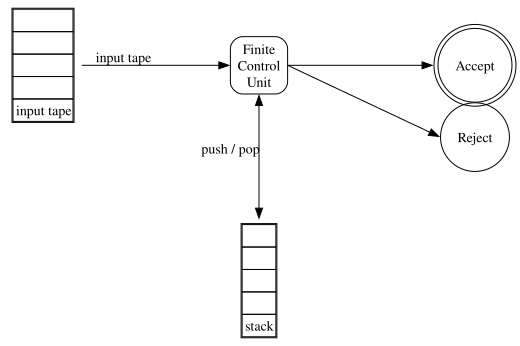

In [160]:
from graphviz import Digraph

pda = Digraph('PDA_components', format='png')
pda.engine = 'neato'
pda.attr(rankdir='LR')

it = r"""<
    <TABLE BORDER="1"  CELLSPACING="0">
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>input tape</TD></TR>
    </TABLE>
>"""

stack = r"""<
    <TABLE BORDER="1"  CELLSPACING="0">
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>stack</TD></TR>
    </TABLE>
>"""


# nodes
# !!! CORRECTED LINE: Use label= and shape='none' !!!
pda.node('in', it, shape='none', pos='0,1!') 
pda.node('cu',  'Finite\nControl\nUnit', shape='box', style='rounded', pos='3,1!')
pda.node('stk', stack,     shape='none',       pos='3,-2!')
pda.node('acc', 'Accept',                 shape='doublecircle', pos='6,1!')
pda.node('rej', 'Reject',                 shape='circle', pos='6,0!')

# edges
pda.edge('in:e', 'cu:w',  label='input tape')
pda.edge('cu:s', 'stk:n', label='push / pop', dir='both', constraint='false')  # vertical-ish
pda.edge('cu:e', 'acc:w')
pda.edge('cu:e', 'rej:w')

# Render the graph to a file
pda

## Formal Definition

A Pushdown Automata is formally defined by 7 tuples

P = (Q, Σ, I, δ, q0, z0, f)

where
- Q : A finite set of states
- Σ : A finite set of input symbols
- I : A finite set of stack alphabet
- δ : The transition function
- q0 : The start state
- z0 : The start stack symbol
- f : The set of final / accepting state

## Transition Function (PDA)

The transition function **δ** takes a triple as input:

- **δ(q, a, X)** where  
  1) **q** is a state in **Q**  
  2) **a** is either an input symbol in **Σ** or **a = ε**  
  3) **X** is a stack symbol (from the stack alphabet)

**Standard formalization (for clarity):**  
$$
\delta:\; Q \times (\Sigma \cup \{\varepsilon\}) \times \Gamma \;\to\; \mathcal{P}(Q \times \Gamma^{*})
$$
Meaning: from state $q$, reading $a$ (or ε), with $X$ on top of the stack, the PDA can move to some $q'$ and replace $X$ by a string $\gamma \in \Gamma^{*}$ (pop $X$, then push $\gamma$).

The output of **δ** is a finite set of pairs **(p, γ)** where:
- **p**: a new state
- **γ**: a string of stack symbols that replaces **X** at the top of the stack

**Examples**
- If **γ = ε**: the stack is popped (remove **X**).
- If **γ = X**: the stack is unchanged.
- If **γ = YZ**: **X** is replaced by **YZ** (i.e., pop **X** then push **Y** and **Z** so the new top is **Y**).


## Graphical Notation

### Finite State Machine


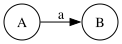

### Pushdown Automaton

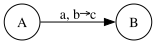


**Notation:** $a, b \to c$

- **Input symbol** ($a$): maybe $\varepsilon$
- **Symbol on top of stack** ($b$): This symbol is popped
- **Symbol pushed onto stack** ($c$):
  - $\varepsilon$ means nothing is pushed
  - $\varepsilon$ for $b$ means stack is neither read nor popped


In [163]:
from IPython.display import display, Markdown
from graphviz import Digraph

# Explanation
markdown_text = r"""
## Graphical Notation

### Finite State Machine
"""
display(Markdown(markdown_text))

# FSM
fsm = Digraph(format='png')
fsm.attr(rankdir='LR')
fsm.node('A', shape='circle')
fsm.node('B', shape='circle')
fsm.edge('A', 'B', label='a')
display(fsm)

# PDA explanation
display(Markdown("### Pushdown Automaton"))

# PDA
pda = Digraph(format='png')
pda.attr(rankdir='LR')
pda.node('A', shape='circle')
pda.node('B', shape='circle')
pda.edge('A', 'B', label='a, b→c')
display(pda)

# Notation explanation
notation = r"""
**Notation:** $a, b \to c$

- **Input symbol** ($a$): maybe $\varepsilon$
- **Symbol on top of stack** ($b$): This symbol is popped
- **Symbol pushed onto stack** ($c$):
  - $\varepsilon$ means nothing is pushed
  - $\varepsilon$ for $b$ means stack is neither read nor popped
"""
display(Markdown(notation))

PDA for  L = { 0^n 1^n  |  n > 0 }

Stack evolution for input `0011` (top shown at the top)

<pre>
Step 0 — after init [ε, ε → Z0]
┌───┐
│Z0 │
└───┘

Step 1 — read 0, push [0, Z0 → 0Z0]
┌───┐
│0  │  ← top
├───┤
│Z0 │
└───┘

Step 2 — read 0, push [0, 0 → 00]
┌───┐
│0  │  ← top
├───┤
│0  │
├───┤
│Z0 │
└───┘

Step 3 — read 1, pop [1, 0 → ε]
┌───┐
│0  │  ← top
├───┤
│Z0 │
└───┘

Step 4 — read 1, pop [1, 0 → ε]
┌───┐
│Z0 │  ← only bottom marker remains
└───┘

Step 5 — ε-move [ε, Z0 → Z0] → accept
</pre>

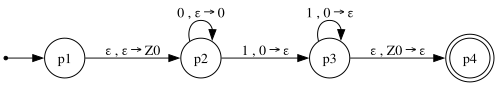

In [168]:
# pip install graphviz   # and have the system 'dot' installed
from graphviz import Digraph

g = Digraph('PDA_0n1n', format='png')
g.attr(rankdir='LR')

# states
g.node('s',  shape='point')
g.node('p1', 'p1', shape='circle')
g.node('p2', 'p2', shape='circle')
g.node('p3', 'p3', shape='circle')
g.node('p4', 'p4', shape='doublecircle')  # accept

g.edge('s','p1')

# ---- Transitions (labels use: [input / stackTop → pushString]) ----
# load bottom marker / or just pass through if it's already there
g.edge('p1','p2', label='ε , ε → Z0')

# push one marker A for each 0 read
g.edge('p2','p2', label='0 , ε → 0')

# first 1 switches to popping phase
g.edge('p2','p3', label='1 , 0 → ε')

# keep popping one A per 1
g.edge('p3','p3', label='1 , 0 → ε')

# accept when input is done and only bottom marker remains
g.edge('p3','p4', label='ε , Z0 → ε')

g

# Turing Machine

### Comparison of Computational Models

| Model | Storage | Read/Write | Movement |
|-------|---------|------------|----------|
| **FSM** | Input tape only | Read-only | One direction → |
| **PDA** | Input tape + Stack | Read input, push/pop stack | One direction → |
| **Turing Machine** | Infinite tape | Read AND write | Left ← or right → |

---

### FSM: The input string

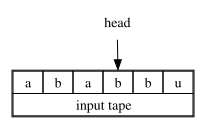

In [204]:
fsm = Digraph('FSM', format='png')
fsm.engine = 'neato'

fsm_tape = r"""<
    <TABLE BORDER="1" CELLSPACING="0">
        <TR><TD WIDTH="30">a</TD><TD WIDTH="30">b</TD><TD WIDTH="30">a</TD><TD WIDTH="30" PORT="head">b</TD><TD WIDTH="30">b</TD><TD WIDTH="30">u</TD></TR>
        <TR><TD COLSPAN="6">input tape</TD></TR>
    </TABLE>
>"""
fsm.node('head', 'head', shape='plaintext', pos='0.2, 1!')
fsm.node('tape', fsm_tape, shape='none', pos='0, 0!')
fsm.edge('head:s', 'tape:head:n',  label='')
fsm

### PDA: Input string + stack

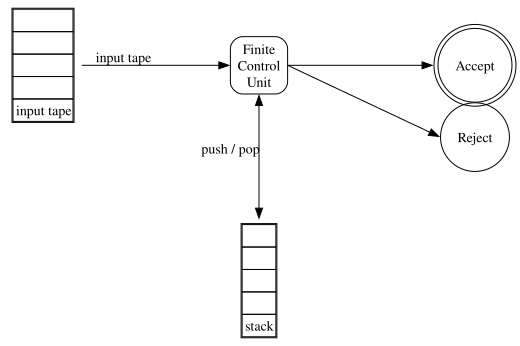

In [193]:
from graphviz import Digraph

pda = Digraph('PDA_components', format='png')
pda.engine = 'neato'
pda.attr(rankdir='LR')

it = r"""<
    <TABLE BORDER="1"  CELLSPACING="0">
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>input tape</TD></TR>
    </TABLE>
>"""

stack = r"""<
    <TABLE BORDER="1"  CELLSPACING="0">
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>   <BR/></TD></TR>
        <TR><TD>stack</TD></TR>
    </TABLE>
>"""


# nodes
# !!! CORRECTED LINE: Use label= and shape='none' !!!
pda.node('in', it, shape='none', pos='0,1!') 
pda.node('cu',  'Finite\nControl\nUnit', shape='box', style='rounded', pos='3,1!')
pda.node('stk', stack,     shape='none',       pos='3,-2!')
pda.node('acc', 'Accept',                 shape='doublecircle', pos='6,1!')
pda.node('rej', 'Reject',                 shape='circle', pos='6,0!')

# edges
pda.edge('in:e', 'cu:w',  label='input tape')
pda.edge('cu:s', 'stk:n', label='push / pop', dir='both', constraint='false')  # vertical-ish
pda.edge('cu:e', 'acc:w')
pda.edge('cu:e', 'rej:w')

# Render the graph to a file
pda


### Turing Machine: 
- **→ A tape** (infinite in both directions)
- **Tape Alphabet:** $\Sigma \subseteq \{0, 1, a, b, +, \times, \ldots\}$
- **The Blank** $\sqcup$ is a special symbol $\notin \Sigma$
  - The blank is used to fill the infinite tape
```
Tape (infinite):
... ⊔ ⊔ a b a a b ⊔ ⊔ ⊔ ...
            ↑
       (tape head)
      ← can move →
```

**Key Feature:** The tape head can:
- Read the current symbol
- Write a new symbol
- Move left or right

### Turing Machine Tape:

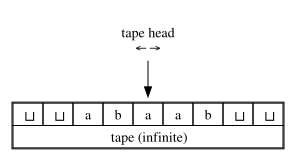

In [208]:
tm = Digraph('TM', format='png')
tm.engine = 'neato'

tm_tape = r"""<
    <TABLE BORDER="1" CELLSPACING="0">
        <TR><TD WIDTH="30">⊔</TD><TD WIDTH="30">⊔</TD><TD WIDTH="30">a</TD><TD WIDTH="30">b</TD><TD WIDTH="30">a</TD><TD WIDTH="30">a</TD><TD WIDTH="30">b</TD><TD WIDTH="30">⊔</TD><TD WIDTH="30">⊔</TD></TR>
        <TR><TD COLSPAN="9">tape (infinite)</TD></TR>
    </TABLE>
>"""

tm.node('head', '\ntape head\n← →', shape='plaintext', pos='0,1.3!')
tm.node('tape', tm_tape, shape='none', pos='0,0!')
tm.edge('head:s', 'tape:n',  label='')
display(Markdown("### Turing Machine Tape:"))
display(tm)

## Initial Configuration (Turing Machine)

**Tape at start:** input string is written on the tape; the rest of the tape is filled with blanks `⊔` “out to infinity”.  
The tape head begins on the first cell of the input.

<pre>
        ↑ head
... | a | b | a | b | a | b | ⊔ | ⊔ | ⊔ | ...
        input string →           blanks →
</pre>

---

### Operations on the Tape

- **Read / Scan** the symbol under the tape head.
- **Write / Update** the symbol under the tape head (replace it with another symbol).
- **Move Left**: shift the tape head one cell to the left.
- **Move Right**: shift the tape head one cell to the right.

## Initial Configuration

The Turing Machine tape starts with:
- **Input string** on the left
- **Blanks** ($\sqcup$) extending to infinity on the right
- **Tape head** positioned at a specific cell

### Operations on the Tape:

1. **Read/Scan** symbol below the tape head
2. **Update/Write** a symbol below the tape head
3. **Move** the tape head one step **LEFT**
4. **Move** the tape head one step **RIGHT**

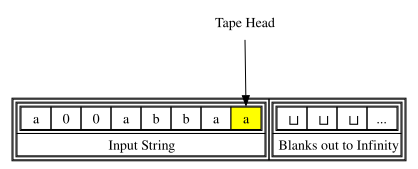

In [239]:
tm = Digraph('TM_Initial', format='png')
tm.engine = 'neato'

# Tape with input string and blanks
tape = r"""<
    <TABLE BORDER="1" CELLSPACING="0">
        <TR>
            <TD>
                <TABLE BORDER="1" CELLSPACING="0">
                    <TR>
                        <TD>
                            <TABLE BORDER="1" CELLSPACING="0">
                                <TR>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30">0</TD>
                                <TD WIDTH="30">0</TD>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30">b</TD>
                                <TD WIDTH="30">b</TD>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30" PORT="head" BGCOLOR="yellow">a</TD>
                                </TR>
                            </TABLE>
                        </TD>
                    </TR>
                    <TR><TD>Input String</TD></TR>
                </TABLE>
            </TD>
            <TD>
                <TABLE BORDER="1" CELLSPACING="0">
                    <TR>
                        <TD>
                           <TABLE BORDER="1" CELLSPACING="0">
                                <TR>
                                    <TD WIDTH="30">⊔</TD>
                                    <TD WIDTH="30">⊔</TD>
                                    <TD WIDTH="30">⊔</TD>
                                    <TD WIDTH="30">...</TD>
                                </TR>
                            </TABLE>
                        </TD>
                    </TR>
                    <TR><TD>Blanks out to Infinity</TD></TR>
                </TABLE>
            </TD>
        </TR>
    </TABLE>
>"""

tm.node('tape', tape, shape='none', pos='5,0!')
tm.node('head', 'Tape Head', shape='plaintext', pos='5.5,1.5!')

tm.edge('head:s', 'tape:head:n', label='')  
display(tm)

## The Control Portion

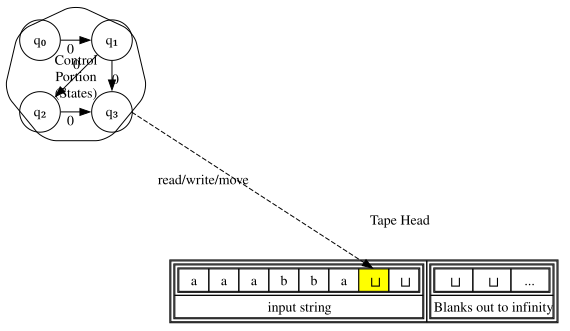

In [243]:
from IPython.display import display, Markdown
from graphviz import Digraph

# Title
display(Markdown("## The Control Portion"))

# Create diagram
g = Digraph('TM_Control', format='png')
g.engine = 'neato'

# Control states (cloud-like representation)
g.node('control', 'Control\nPortion\n(States)', shape='septagon', style='rounded', 
       width='2', height='2', pos='2,4!')

# Show some sample states inside
g.node('q0', 'q₀', shape='circle', pos='1.5,4.5!')
g.node('q1', 'q₁', shape='circle', pos='2.5,4.5!')
g.node('q2', 'q₂', shape='circle', pos='1.5,3.5!')
g.node('q3', 'q₃', shape='circle', pos='2.5,3.5!')

# Add some transitions
g.edge('q0', 'q1', label='0', constraint='false')
g.edge('q1', 'q3', label='0', constraint='false')
g.edge('q2', 'q3', label='0', constraint='false')
g.edge('q1', 'q2', label='0', constraint='false')

# Tape
tape = r"""<
    <TABLE BORDER="1" CELLSPACING="0">
        <TR>
            <TD>
                <TABLE BORDER="1" CELLSPACING="0">
                    <TR>
                        <TD>
                            <TABLE BORDER="1" CELLSPACING="0">
                                <TR>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30">b</TD>
                                <TD WIDTH="30">b</TD>
                                <TD WIDTH="30">a</TD>
                                <TD WIDTH="30" PORT="head" BGCOLOR="yellow">⊔</TD>
                                <TD WIDTH="30">⊔</TD>
                                </TR>
                            </TABLE>
                        </TD>
                    </TR>
                    <TR><TD>input string</TD></TR>
                </TABLE>
            </TD>
            <TD>
                <TABLE BORDER="1" CELLSPACING="0">
                    <TR>
                        <TD>
                           <TABLE BORDER="1" CELLSPACING="0">
                                <TR>
                                    <TD WIDTH="30">⊔</TD>
                                    <TD WIDTH="30">⊔</TD>
                                    <TD WIDTH="30">...</TD>
                                </TR>
                            </TABLE>
                        </TD>
                    </TR>
                    <TR><TD>Blanks out to infinity</TD></TR>
                </TABLE>
            </TD>
        </TR>
    </TABLE>
>"""

g.node('tape', tape, shape='none', pos='6,1!')
g.node('head_label', 'Tape Head', shape='plaintext', pos='6.5,2!')

# Connection
g.edge('control', 'tape:head', label='read/write/move', style='dashed')

display(g)


The control portion similar to **FSM** or **PDA** — **the PROGRAM**.  
It is **deterministic**.

## Rules of Operation - 1

At each step of the computation:

1. **Read** the current symbol
2. **Update** (i.e., write) the same cell
3. **Move** exactly one cell either **LEFT** or **RIGHT**

### Boundary Condition:

If we are at the **left end** of the tape, and trying to move **LEFT**, then do not move. Stay at the left end.


### Transition Notation:

**Format:** `a → b, D`

- **a**: Symbol to Read
- **b**: Symbol to Write  
- **D**: Direction to Move (LEFT or RIGHT)

### Example Transitions:

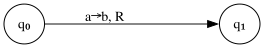

In [251]:
g = Digraph('TM_Transitions', format='png')
g.engine = 'neato'

# Example 1: Read a, write b, move right
g.node('q0', 'q₀', shape='circle', pos='0,2!')
g.node('q1', 'q₁', shape='circle', pos='3,2!')
g.edge('q0', 'q1', label='a→b, R')
display(g)

- a: Symbol to Read
- b: Symbol to Write
- R: Direction to Move LEFT or RIGHT

### If you don't want to update the cell, JUST WRITE THE SAME SYMBOL

**Example:** Read `1`, write `1`, move LEFT

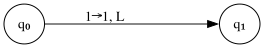

In [252]:
g2 = Digraph('TM_NoChange', format='png')
g2.engine = 'neato'

g2.node('q0', 'q₀', shape='circle', pos='0,0!')
g2.node('q1', 'q₁', shape='circle', pos='3,0!')
g2.edge('q0', 'q1', label='1→1, L')

display(g2)

## Rules of Operation - 2

### Control is with a sort of FSM

The Turing Machine control unit has:

- **Initial State**
- **Final States** (there are **two** final states):
  1. The **ACCEPT STATE**
  2. The **REJECT STATE**

### Computation can either:

1. **HALT and ACCEPT** ✓
2. **HALT and REJECT** ✗
3. **LOOP** (the machine fails to HALT) ∞

## Turing Machine Formal Definition

A Turing Machine can be defined as a set of **7 tuples**:

$$M = (Q, \Sigma, \Gamma, \delta, q_0, b, F)$$

Where:

- **$Q$**: Non-empty set of **States**

- **$\Sigma$**: Non-empty set of **Symbols** (input alphabet)

- **$\Gamma$**: Non-empty set of **Tape Symbols** (where $\Sigma \subseteq \Gamma$)

- **$\delta$**: **Transition function** defined as:
  $$\delta: Q \times \Gamma \to \Gamma \times \{L, R\} \times Q$$
  
  This means: from a state in $Q$ reading a tape symbol in $\Gamma$, the machine writes a new symbol in $\Gamma$, moves left (L) or right (R), and transitions to a new state in $Q$.

- **$q_0$**: **Initial State** (where $q_0 \in Q$)

- **$b$**: **Blank Symbol** (where $b \in \Gamma$ and $b \notin \Sigma$)

- **$F$**: Set of **Final States** (Accept state & Reject state, where $F \subseteq Q$)

---

### Production Rule of Turing Machine

Thus, the production rule of a Turing Machine will be written as:

$$\delta(q_0, a) \to (q_1, y, R)$$

**Interpretation:**
- In state $q_0$, reading symbol $a$
- Write symbol $y$
- Move **Right** (R)
- Transition to state $q_1$

---

### Key Points:

1. **$\Sigma \subseteq \Gamma$**: The input alphabet is a subset of the tape alphabet
2. **$b \in \Gamma, b \notin \Sigma$**: The blank symbol is on the tape but not in the input
3. **Transition format**: $(current\_state, read\_symbol) \to (new\_state, write\_symbol, direction)$
4. **Direction**: Either $L$ (Left) or $R$ (Right)